In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import data
from check_submission import check_all

ROOT = Path.cwd()
TRACKS = ["off_market", "list_aware"]
# Walk-forward validation: each of these months is predicted by models trained only
# on the sales before that month, the same way the real test works.
VALIDATION_MONTHS = pd.period_range("2025-12", "2026-05", freq="M")


In [2]:
def validate(
    modelspecs,
    make_model_func=None,
    mode="expanding",
    train_cutoff=None,
    horizon_months=4,
):
    from models.model import make_model

    if make_model_func is None:
        make_model_func = make_model

    listings = data.load("listings")
    results = []
    model_list = []

    if mode == "expanding":
        # Original validation: retrain for every evaluation month
        months = VALIDATION_MONTHS

    elif mode == "fixed_origin":
        # Train once and freeze the model for the entire horizon
        cutoff = pd.Timestamp(train_cutoff)

        if cutoff != cutoff.to_period("M").start_time:
            raise ValueError("train_cutoff must be the first day of a month.")

        if horizon_months < 1:
            raise ValueError("horizon_months must be positive.")

        months = pd.period_range(
            start=cutoff.to_period("M"),
            periods=horizon_months,
            freq="M",
        )

        train = listings.loc[
            listings["date_sold"] < cutoff
        ]

        if train.empty:
            raise ValueError("No training sales before train_cutoff.")

        # Fit each track exactly ONCE
        fixed_models = [
            make_model_func(track, modelspecs=modelspecs).fit(train)
            for track in TRACKS
        ]

        model_list.append(fixed_models)

        print(
            f"Fixed origin: trained on {len(train):,} sales "
            f"before {cutoff.date()}"
        )

    else:
        raise ValueError("mode must be 'expanding' or 'fixed_origin'.")

    for month in months:
        homes = listings.loc[
            listings["date_sold"].dt.to_period("M") == month
        ]

        if mode == "expanding":
            train = listings.loc[
                listings["date_sold"] < month.start_time
            ]

            models = [
                make_model_func(track, modelspecs=modelspecs).fit(train)
                for track in TRACKS
            ]

            model_list.append(models)
        else:
            # Reuse the SAME fitted models for every month
            models = fixed_models

        for track, model in zip(TRACKS, models):
            predicted = model.predict(
                data.hide_answers(homes, track)
            )

            results.append(pd.DataFrame({
                "ml_num": homes["ml_num"],
                "track": track,
                "month": str(month),
                "house_type_name": homes["house_type_name"],
                "sold_price": homes["sold_price"],
                "predicted_price": np.round(predicted),
            }))

        if mode == "expanding":
            print(
                f"{month}: trained on {len(train):,} earlier sales, "
                f"predicted {len(homes):,} homes"
            )
        else:
            print(
                f"{month}: reused frozen models, "
                f"predicted {len(homes):,} homes"
            )

    return pd.concat(results, ignore_index=True), model_list

def bootstrap_ci(values, statistic, repeats=1000):
    """95% interval: recompute the statistic on 1,000 resamples of the homes
    (drawn with replacement) and keep the middle 95% of the results."""
    rng = np.random.default_rng(0)
    results = [statistic(rng.choice(values, size=len(values))) for _ in range(repeats)]
    return [round(float(x), 2) for x in np.percentile(results, [2.5, 97.5])]

def metrics(predictions):
    """Scores for one track. Errors are in percent of the sold price."""
    signed = 100 * (predictions["predicted_price"] - predictions["sold_price"]) / predictions["sold_price"]
    absolute = signed.abs().to_numpy()
    return {
        "n": len(predictions),
        "mape": round(float(np.mean(absolute)), 2),          # mean absolute % error
        "mape_95ci": bootstrap_ci(absolute, np.mean),
        "mdape": round(float(np.median(absolute)), 2),       # median absolute % error
        "mdape_95ci": bootstrap_ci(absolute, np.median),
        "median_signed_error": round(float(np.median(signed)), 2),  # above 0: predicts too high
    }
def report(df):
    # Accept results from earlier notebook runs without refitting the models.
    predictions = pd.concat(df, ignore_index=True) if isinstance(df, list) else df
    scores = {track: metrics(predictions[predictions["track"] == track]) for track in TRACKS}

    (ROOT / "reports").mkdir(exist_ok=True)
    (ROOT / "reports" / "validation_report.json").write_text(json.dumps(scores, indent=2))
    lines = [
        "# Validation report", "",
        f"Walk-forward validation, {VALIDATION_MONTHS[0]} to {VALIDATION_MONTHS[-1]}: each month was "
        "predicted by models trained only on the sales before it.",
        "Errors are (predicted - sold) / sold. Brackets: bootstrap 95% interval.", "",
        "| Track | Homes | MAPE | MdAPE | Median signed error |", "|---|---|---|---|---|"]
    for track, s in scores.items():
        lines.append(f"| {track} | {s['n']:,} | {s['mape']:.2f}% ({s['mape_95ci'][0]:.2f} to {s['mape_95ci'][1]:.2f}) "
                     f"| {s['mdape']:.2f}% ({s['mdape_95ci'][0]:.2f} to {s['mdape_95ci'][1]:.2f}) "
                     f"| {s['median_signed_error']:+.2f}% |")
    lines += [
        "", "MAPE: mean absolute percentage error. MdAPE: median absolute percentage error.",
        "A median signed error above 0 means the model tends to predict too high.",
        "The intervals treat homes as independent. Homes sold in the same month share the same",
        "market swings, so the real uncertainty is somewhat wider.", "",
        "![Error by price range](../figures/error_by_price_range.png)", ""]
    (ROOT / "reports" / "validation_report.md").write_text("\n".join(lines))
    write_latex_table(scores)
    error_by_price_range(predictions)
    print("\n".join(lines))
    print("Wrote reports/validation_report.md, reports/validation_report.json, reports/results_table.tex "
          "and figures/error_by_price_range.png")


def write_latex_table(scores):
    """The same scores as a LaTeX table, for report/report.tex to include."""
    rows = []
    for track, s in scores.items():
        name = track.replace("_", "-")
        rows.append(f"{name} & {s['n']:,} & {s['mdape']:.2f} ({s['mdape_95ci'][0]:.2f}--{s['mdape_95ci'][1]:.2f}) "
                    f"& {s['mape']:.2f} ({s['mape_95ci'][0]:.2f}--{s['mape_95ci'][1]:.2f}) "
                    f"& {s['median_signed_error']:+.2f} \\\\")
    table = "\n".join([
        "% Written by `python run.py report`. Do not edit by hand: rerun the command instead.",
        "\\begin{tabular}{lrccc}", "\\hline",
        "Track & Homes & MdAPE \\% (95\\% CI) & MAPE \\% (95\\% CI) & Median signed error \\% \\\\", "\\hline",
        *rows, "\\hline", "\\end{tabular}"])
    (ROOT / "reports" / "results_table.tex").write_text(table + "\n")


def error_by_price_range(predictions):
    """Figure: how big the errors are, from the cheapest tenth of homes to the dearest.

    Want more figures? Copy this function and group the errors by something else:
    house_type_name, month, or community (add it to the predictions file in validate()).
    """
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(8, 4.5))
    colours = {"off_market": "#2a78d6", "list_aware": "#eb6834"}
    for track in TRACKS:
        rows = predictions[predictions["track"] == track]
        error = 100 * (rows["predicted_price"] - rows["sold_price"]).abs() / rows["sold_price"]
        decile = pd.qcut(rows["sold_price"], 10, labels=False) + 1   # 1 = cheapest tenth
        by_decile = error.groupby(decile)
        middle = by_decile.median()
        ax.plot(middle.index, middle.values, marker="o", linewidth=2, color=colours[track], label=track)
        ax.fill_between(middle.index, by_decile.quantile(0.25), by_decile.quantile(0.75),
                        color=colours[track], alpha=0.15, linewidth=0)
    prices = rows["sold_price"].groupby(decile).median()
    ax.set_xticks(prices.index, [f"{d}\n${p / 1e6:.2f}M" for d, p in prices.items()])
    ax.set_xlabel("Sold-price decile (1 = cheapest tenth of homes), with its median price")
    ax.set_ylabel("Absolute % error\n(line: median, band: middle 50%)")
    ax.set_title(f"Validation error by price range, {VALIDATION_MONTHS[0]} to {VALIDATION_MONTHS[-1]}")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    (ROOT / "figures").mkdir(exist_ok=True)
    fig.savefig(ROOT / "figures" / "error_by_price_range.png", dpi=150)
    plt.close(fig)

In [3]:
from models.boost_regressor import CatBoostRegressor, LightGBMRegressor, XGBoostRegressor
from models.arima import ArimaResidualModel
from models.model import make_model
from models.direct_listing import DirectListingModel
from models.model import OffMarketModel

CATBOOST_PARAMS = {
    "iterations": 900,
    "depth": 6,
    "learning_rate": 0.04,
    "l2_leaf_reg": 5,
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
}

LIGHTGBM_PARAMS = {
    "n_estimators": 900,
    "learning_rate": 0.04,
    "max_depth": 6,
    "num_leaves": 31,
    "min_child_samples": 40,
    "reg_lambda": 5.0,
    "reg_alpha": 0.0,
    "subsample": 0.9,
    "subsample_freq": 1,
    "colsample_bytree": 0.9,
    "max_bin": 255,
    "objective": "regression",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

XGBOOST_PARAMS = {
    "n_estimators": 900,
    "learning_rate": 0.04,
    "max_depth": 6,
    "min_child_weight": 5,
    "reg_lambda": 5.0,
    "reg_alpha": 0.0,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "tree_method": "hist",
    "grow_policy": "depthwise",
    "device": "cpu",
    "enable_categorical": True,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
}
0
LGB_MODEL_SPECS = [
    (LightGBMRegressor, "Xpt_spatiotemporal__selected_binary", {'n_estimators': 1800, 'learning_rate': 0.052995139011091236, 'max_depth': 6, 'num_leaves': 40, 'min_child_samples': 30, 'reg_lambda': 16.19372143031597, 'reg_alpha': 0.0, 'subsample': 0.8349167453037107, 'subsample_freq': 1, 'colsample_bytree': 0.953443325579757, 'max_bin': 255, 'objective': 'regression', 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}),
]
XGB_MODEL_SPECS = [
    (XGBoostRegressor, "Xpt_spatiotemporal__selected_binary", {'n_estimators': 700, 'learning_rate': 0.09522271657253033, 'max_depth': 8, 'min_child_weight': 16.684619386293466, 'reg_lambda': 19.50331236061207, 'reg_alpha': 0.0, 'subsample': 0.9804685587557792, 'colsample_bytree': 0.8994749947027713, 'tree_method': 'hist', 'grow_policy': 'depthwise', 'device': 'cpu', 'enable_categorical': True, 'objective': 'reg:squarederror', 'random_state': 42, 'n_jobs': -1, 'verbosity': 0}),
]
CAT_MODEL_SPECS = [
    (CatBoostRegressor, 'Xpt_spatiotemporal', {'iterations': 1400, 'depth': 8, 'learning_rate': 0.07127609366218435, 'l2_leaf_reg': 4.14053058084107, 'loss_function': 'RMSE', 'random_seed': 42, 'verbose': False, 'allow_writing_files': False, 'task_type': 'CPU', 'thread_count': -1, 'random_strength': 0.580328206016201}),
]
MODEL_SPECS = XGB_MODEL_SPECS
def custom_make_model(track, modelspecs=None):
    specs = MODEL_SPECS if modelspecs is None else modelspecs

    if track == "list_aware":
        return DirectListingModel(
            target="ratio",
            modelspecs=specs,
        )

    return OffMarketModel(
        specs,
        center_target=True,
    )


# Default to already-saved XGBoost model snapshots instead of fitting twice.
RUN_BASELINE_TRAINING = False
if RUN_BASELINE_TRAINING:
    predictions, models = validate(
        modelspecs=MODEL_SPECS,
        make_model_func=custom_make_model,
    )

In [8]:
import numpy as np
import pandas as pd
from pathlib import Path

import data
from save_model import load_model, model_info


def recover_validation(
    model_name="XGBoost_text_binary",
    save_predictions=True,
):
    # 1. Restore the fitted models
    models = load_model(model_name)
    info = model_info(model_name)

    months = pd.period_range("2025-12", "2026-05", freq="M")
    tracks = ["off_market", "list_aware"]

    # 2. Check that the saved models match our validation setup
    assert len(models) == len(months), "Unexpected number of saved months"
    assert all(len(pair) == 2 for pair in models), "Expected two tracks per month"

    metadata = info.get("metadata", {})
    if metadata.get("validation_months"):
        assert metadata["validation_months"] == [str(m) for m in months]
    if metadata.get("tracks"):
        assert metadata["tracks"] == tracks

    # 3. Load original validation properties
    listings = data.load("listings")
    sale_months = listings["date_sold"].dt.to_period("M")

    results = []

    # 4. Reconstruct predictions without fitting
    for month, month_models in zip(months, models):
        homes = listings.loc[sale_months == month]

        for track, model in zip(tracks, month_models):
            hidden = data.hide_answers(homes, track)
            predicted = np.round(model.predict(hidden))

            results.append(pd.DataFrame({
                "ml_num": homes["ml_num"].to_numpy(),
                "track": track,
                "month": str(month),
                "house_type_name": homes["house_type_name"].to_numpy(),
                "sold_price": homes["sold_price"].to_numpy(),
                "predicted_price": predicted,
            }))

        print(f"{month}: recovered {len(homes):,} homes")

    predictions = pd.concat(results, ignore_index=True)

    # 5. Save recovered predictions
    if save_predictions:
        path = Path("outputs/validation_predictions.csv")
        path.parent.mkdir(parents=True, exist_ok=True)
        predictions.to_csv(path, index=False)
        print(f"\nSaved predictions to {path}")

    return predictions, models


from models.spatiotemporal_features import ComparableSalesFeatures

# Restore original behaviour for legacy saved models
ComparableSalesFeatures.age_filter_first = False
ComparableSalesFeatures.min_same_type_neighbors = 0

# Restore the same variables used by the main notebook
if not RUN_BASELINE_TRAINING:
    predictions, models = recover_validation()
else:
    print("Using freshly fitted baseline models")

display(predictions.head())

2025-12: recovered 1,238 homes
2026-01: recovered 1,058 homes
2026-02: recovered 1,442 homes
2026-03: recovered 1,816 homes


KeyboardInterrupt: 

In [7]:
report(predictions)

# Validation report

Walk-forward validation, 2025-12 to 2026-05: each month was predicted by models trained only on the sales before it.
Errors are (predicted - sold) / sold. Brackets: bootstrap 95% interval.

| Track | Homes | MAPE | MdAPE | Median signed error |
|---|---|---|---|---|
| off_market | 10,069 | 10.38% (10.18 to 10.58) | 7.82% (7.64 to 7.99) | +0.41% |
| list_aware | 10,069 | 5.20% (5.12 to 5.29) | 4.17% (4.09 to 4.26) | +0.51% |

MAPE: mean absolute percentage error. MdAPE: median absolute percentage error.
A median signed error above 0 means the model tends to predict too high.
The intervals treat homes as independent. Homes sold in the same month share the same
market swings, so the real uncertainty is somewhat wider.

![Error by price range](../figures/error_by_price_range.png)

Wrote reports/validation_report.md, reports/validation_report.json, reports/results_table.tex and figures/error_by_price_range.png


In [10]:
# Share these results with notebook.ipynb and the existing report command.
output_path = ROOT / "outputs" / "validation_predictions.csv"
output_path.parent.mkdir(exist_ok=True)
predictions.to_csv(output_path, index=False)

## Full-strength spatiotemporal individual-model comparison (off-market only)

This experiment keeps the original 700-tree XGBoost reference from `predictions, models`. No baseline retraining.

**Full-history refits:** `spacetime_splines` (3-month winner), `geo_context`, original `combined` (contains splines), `comp_type_quota` and `comp_both` (historical reference controls). Each has the **identical tuned estimator settings**, median-centered log-price target, same chronological training cutoff, same training records and held-out properties.

**Previously evaluated corrections:** `tensor_gam` and `rbf_ridge` are independently recalibrated using the three preceding months of truly out-of-time XGBoost errors. They correct **original baseline XGBoost**, not spline XGBoost. No combination is evaluated in this full-strength run.

The output contains independent per-variant/month predictions with restart-safe caching, pooled and monthly MAPE/MdAPE, paired bootstrap differences and house-type diagnostics. The new results live at `outputs/spacetime_full_feature_comparison/` and do not replace your original validation outputs or saved models.

By default `Run All` restores the trusted `saved_models/XGBoost_text_binary` snapshot rather than training a second XGBoost baseline. You can set `RUN_BASELINE_TRAINING=True` in cell 2 to retrain from scratch. The save step is opt-in so existing model files are not overwritten.

**Separate combination experiment:** `spacetime_combination_screen.ipynb` uses only 10k samples / 220 trees for spline + geo, spline + quota, spline + market, etc. before promoting any combination to the expensive final validation.

**Caution:** Dec 2025–May 2026 has already been consulted; treat this as confirmation rather than an untouched final test.


In [8]:
# Full-history: each feature and residual model evaluated individually.
RUN_FULL_FEATURE_COMPARISON = False  # previous full run already completed

if RUN_FULL_FEATURE_COMPARISON:
    from spacetime_full_feature_comparison import compare_full_spacetime_models
    from IPython.display import display

    full_pooled, full_monthly, full_by_type, full_predictions = compare_full_spacetime_models(
        baseline_predictions=predictions,
        fitted_models=models,
        months=VALIDATION_MONTHS,
        feature_variants=(
            "baseline",
            "spacetime_splines",
            "geo_context",
            "combined",
            "comp_type_quota",
            "comp_both",
        ),
        residual_variants=("tensor_gam", "rbf_ridge"),
        mode="expanding",
        calibration_months=3,
        calibration_cap=None,
        residual_strength=0.5,
        bootstrap_repeats=500,
        output_dir="outputs/spacetime_full_feature_comparison",
        resume=True,
    )
    display(full_pooled)
    display(full_monthly)
    display(full_by_type)
    print("Results saved in outputs/spacetime_full_feature_comparison/")



2025-12: 1,238 holdouts; full history before 2025-12-01
  spacetime_splines: fitting 700-tree spec to 139,931 sales
  geo_context: fitting 700-tree spec to 139,931 sales
  combined: fitting 700-tree spec to 139,931 sales
  comp_type_quota: fitting 700-tree spec to 139,931 sales
  comp_both: fitting 700-tree spec to 139,931 sales
    2025-09: fitting tuned base model on 133,779 earlier sales; predicting 2,035 unseen homes
    2025-10: fitting tuned base model on 135,814 earlier sales; predicting 2,250 unseen homes
    2025-11: fitting tuned base model on 138,064 earlier sales; predicting 1,867 unseen homes
  finished 2025-12

2026-01: 1,058 holdouts; full history before 2026-01-01
  spacetime_splines: fitting 700-tree spec to 141,169 sales
  geo_context: fitting 700-tree spec to 141,169 sales
  combined: fitting 700-tree spec to 141,169 sales
  comp_type_quota: fitting 700-tree spec to 141,169 sales
  comp_both: fitting 700-tree spec to 141,169 sales
    2025-12: reusing existing fitte

,homes,mape,mdape,median_signed,arm,variant,delta_mdape_pp,delta_mape_pp,mean_paired_ape_delta,homes_improved_fraction,delta_mdape_ci_low,delta_mdape_ci_high,delta_mape_ci_low,delta_mape_ci_high,months_better_mdape
0,10069,10.019250,7.588816,0.407211,feature,spacetime_splines,-0.229425,-0.362288,-0.362288,0.527858,-0.407554,-0.080800,-0.445519,-0.284421,6
1,10069,10.234494,7.621123,0.402116,feature,geo_context,-0.197119,-0.147043,-0.147043,0.516834,-0.336013,-0.050441,-0.223616,-0.068028,6
2,10069,10.356925,7.801095,0.304044,residual,tensor_gam,-0.017146,-0.024613,-0.024613,0.498957,-0.085074,0.064594,-0.041311,-0.007828,3
3,10069,10.267962,7.815925,0.483198,feature,combined,-0.002316,-0.113576,-0.113576,0.507101,-0.180808,0.162183,-0.209906,-0.020337,5
4,10069,10.381538,7.818242,0.408726,feature,baseline,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
5,10069,10.360145,7.850914,0.276124,residual,rbf_ridge,0.032672,-0.021393,-0.021393,0.499255,-0.044927,0.110743,-0.040671,-0.000111,2
6,10069,10.562967,8.088569,0.454084,feature,comp_type_quota,0.270327,0.181429,0.181429,0.483067,0.101366,0.428660,0.062996,0.275878,0
7,10069,10.647414,8.155765,0.309378,feature,comp_both,0.337523,0.265876,0.265876,0.479591,0.141122,0.491685,0.156103,0.370385,0


,homes,mape,mdape,median_signed,month,arm,variant,delta_mdape_pp,delta_mape_pp
0,1238,10.572629,7.953344,1.559994,2025-12,residual,rbf_ridge,-0.325383,-0.348547
1,1238,10.593873,7.954467,1.725276,2025-12,residual,tensor_gam,-0.324260,-0.327303
2,1238,10.617222,8.003067,2.997089,2025-12,feature,geo_context,-0.275660,-0.303953
3,1238,10.557862,8.184548,2.969956,2025-12,feature,spacetime_splines,-0.094179,-0.363314
4,1238,10.758780,8.249434,3.508063,2025-12,feature,combined,-0.029293,-0.162395
5,1238,10.921176,8.278727,2.916296,2025-12,feature,baseline,0.000000,0.000000
6,1238,11.073121,8.507402,3.476305,2025-12,feature,comp_type_quota,0.228675,0.151946
7,1238,11.220694,8.570544,3.411712,2025-12,feature,comp_both,0.291817,0.299518
8,1058,9.947284,7.394714,0.999829,2026-01,feature,spacetime_splines,-0.329683,-0.402283
9,1058,10.140594,7.536393,0.146382,2026-01,feature,combined,-0.188004,-0.208973


,homes,mape,mdape,median_signed,house_type_name,arm,variant,delta_mdape_pp,delta_mape_pp
0,48,18.583158,12.634448,-3.030243,Co-Op Apt,residual,rbf_ridge,-0.554036,0.136932
1,48,18.161121,12.787432,-2.975226,Co-Op Apt,feature,geo_context,-0.401052,-0.285104
2,48,18.579053,12.866223,-2.768359,Co-Op Apt,residual,tensor_gam,-0.322261,0.132828
3,48,19.935290,12.889698,-1.895429,Co-Op Apt,feature,comp_type_quota,-0.298785,1.489065
4,48,18.446225,13.188484,-1.188152,Co-Op Apt,feature,baseline,0.000000,0.000000
5,48,20.331036,13.301718,-2.328882,Co-Op Apt,feature,comp_both,0.113235,1.884811
6,48,18.689882,13.347487,0.973267,Co-Op Apt,feature,spacetime_splines,0.159003,0.243656
7,48,20.238399,14.393685,1.130542,Co-Op Apt,feature,combined,1.205201,1.792173
8,4843,8.763092,6.485410,1.303846,Condo Apt,feature,spacetime_splines,-0.307739,-0.430327
9,4843,8.968478,6.661043,1.287038,Condo Apt,feature,geo_context,-0.132105,-0.224940


Results saved in outputs/spacetime_full_feature_comparison/


In [ ]:
# Optional: keep the previously saved trusted baseline intact by default.
SAVE_BASELINE_MODELS = False
if SAVE_BASELINE_MODELS:
    from save_model import save_model
    save_model(
        models, "XGBoost_text_binary",
        metadata={
            "features": "Xpt_spatiotemporal__selected_binary",
            "tracks": list(TRACKS),
            "validation_months": [str(m) for m in VALIDATION_MONTHS],
            "mode": "expanding",
        },
    )


                            Homes   MAPE  MdAPE
track      horizon month                       
list_aware 1       2026-02   1442   5.44   4.31
           2       2026-03   1816   5.39   4.20
           3       2026-04   2224   5.35   4.31
           4       2026-05   2291   5.57   4.50
off_market 1       2026-02   1442  11.46   8.90
           2       2026-03   1816  11.53   8.84
           3       2026-04   2224  11.81   9.29
           4       2026-05   2291  12.27   9.69


Xpt -> BoostingFeatures
Xpt_spatiotemporal -> RatioComparableFeatures
Stages: 1
Feature provider: RatioComparableFeatures
Trained feature names:
['square_feet', 'bedrooms', 'washrooms', 'parking', 'garage_count', 'lot_front', 'lot_depth', 'lot_area', 'longitude', 'latitude', 'months_since_2021', 'season_sin', 'season_cos', 'log_list_price', 'house_type_name', 'house_style', 'municipality', 'community', 'garage', 'tfidf_0', 'tfidf_1', 'tfidf_2', 'tfidf_3', 'tfidf_4', 'tfidf_5', 'tfidf_6', 'tfidf_7', 'tfidf_8', 'tfidf_9', 'tfidf_10', 'tfidf_11', 'tfidf_12', 'tfidf_13', 'tfidf_14', 'tfidf_15', 'tfidf_16', 'tfidf_17', 'tfidf_18', 'tfidf_19', 'tfidf_20', 'tfidf_21', 'tfidf_22', 'tfidf_23', 'tfidf_24', 'tfidf_25', 'tfidf_26', 'tfidf_27', 'tfidf_28', 'tfidf_29', 'tfidf_30', 'tfidf_31', 'tfidf_32', 'tfidf_33', 'tfidf_34', 'tfidf_35', 'tfidf_36', 'tfidf_37', 'tfidf_38', 'tfidf_39', 'tfidf_40', 'tfidf_41', 'tfidf_42', 'tfidf_43', 'tfidf_44', 'tfidf_45', 'tfidf_46', 'comp_log_price', 'comp_log_pp

## Full-history spline + model-specific Tensor GAM experiment

The smaller combination screen favored **XGBoost + spatiotemporal splines + Tensor GAM**, with **XGBoost + splines + geographic context + Tensor GAM** also promising. This separate comparison evaluates both on the original six chronological validation months using the entire historical training population and the same tuned 700-tree XGBoost specifications.

**Compared arms:** original XGBoost baseline (already fitted); splines only; splines+geo only; splines+Tensor GAM; splines+geo+Tensor GAM.

Each Tensor GAM is calibrated using out-of-time **residuals of its own feature model** on the three prior sold-month cohorts. Prior calibration homes are predicted with full-strength feature models fitted only on sales completed before that month. The script checks provenance before reusing predictions from `outputs/spacetime_full_feature_comparison`; new computations and resumable caches go to `outputs/spacetime_full_spline_gam` and do not touch earlier results.

Run the following cell **after** loading `predictions, models` in the saved-model recovery cell above. Results include comparison to both the original XGBoost and each GAM's respective feature-only baseline. The earlier full-feature comparison is now off by default to avoid repeating it.

**Caveat:** This is another examination of the already-consulted Dec 2025–May 2026 data; it is not an untouched holdout.


In [9]:
# Run the two full-strength GAM corrections on their corresponding feature bases.
RUN_FULL_SPLINE_GAM_COMPARISON = True

if RUN_FULL_SPLINE_GAM_COMPARISON:
    from spacetime_full_gam_comparison import compare_full_spline_gam
    from IPython.display import display

    gam_pooled, gam_monthly, gam_by_type, gam_predictions = compare_full_spline_gam(
        baseline_predictions=predictions,
        fitted_models=models,
        months=VALIDATION_MONTHS,
        calibration_months=3,
        calibration_cap=None,
        residual_strength=0.5,
        bootstrap_repeats=500,
        previous_feature_dir="outputs/spacetime_full_feature_comparison",
        output_dir="outputs/spacetime_full_spline_gam",
        resume=True,
    )
    display(gam_pooled)
    display(gam_monthly)
    display(gam_by_type)
    print("Saved results to outputs/spacetime_full_spline_gam/")


Verified old spline cache: outputs\spacetime_full_feature_comparison

2025-12: 1,238 held-out homes
  2025-12 splines: reused verified earlier full model
  2025-09 splines: fitting full model on 133,779 earlier sales
  2025-10 splines: fitting full model on 135,814 earlier sales
  2025-11 splines: fitting full model on 138,064 earlier sales
  2025-12 splines_tensor_gam: fitted on 6,152 prior OOT errors
  2025-12 splines_geo: fitting full model on 139,931 earlier sales
  2025-09 splines_geo: fitting full model on 133,779 earlier sales
  2025-10 splines_geo: fitting full model on 135,814 earlier sales
  2025-11 splines_geo: fitting full model on 138,064 earlier sales
  2025-12 splines_geo_tensor_gam: fitted on 6,152 prior OOT errors

2026-01: 1,058 held-out homes
  2026-01 splines: reused verified earlier full model
  2026-01 splines_tensor_gam: fitted on 5,355 prior OOT errors
  2026-01 splines_geo: fitting full model on 141,169 earlier sales
  2026-01 splines_geo_tensor_gam: fitted on 

,homes,mape,mdape,median_signed,arm,variant,delta_mdape_pp,delta_mape_pp,mean_paired_ape_delta,homes_improved_fraction,...,delta_mape_ci_high,months_better_mdape,parent_model,delta_parent_mdape_pp,delta_parent_mape_pp,parent_homes_improved_fraction,delta_parent_mdape_ci_low,delta_parent_mdape_ci_high,delta_parent_mape_ci_low,delta_parent_mape_ci_high
0,10069,10.033904,7.485654,0.338248,residual,splines_geo_tensor_gam,-0.332588,-0.347634,-0.347634,0.528255,...,-0.258721,6,splines_geo,-0.045900,-0.023782,0.496474,-0.134003,0.018663,-0.039905,-0.008203
1,10069,10.057686,7.531554,0.472075,feature,splines_geo,-0.286688,-0.323852,-0.323852,0.521402,...,-0.235462,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10069,10.019250,7.588816,0.407211,feature,splines,-0.229425,-0.362288,-0.362288,0.527858,...,-0.284421,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10069,9.985529,7.589384,0.241078,residual,splines_tensor_gam,-0.228858,-0.396009,-0.396009,0.528652,...,-0.313524,6,splines,0.000568,-0.033721,0.498560,-0.074040,0.091119,-0.049507,-0.015556
4,10069,10.381538,7.818242,0.408726,feature,baseline,0.000000,0.000000,0.000000,0.000000,...,0.000000,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,homes,mape,mdape,median_signed,month,arm,variant,delta_mdape_pp,delta_mape_pp,delta_parent_mdape_pp,delta_parent_mape_pp
0,1238,10.204878,7.744729,2.209649,2025-12,residual,splines_geo_tensor_gam,-0.533998,-0.716297,-0.258223,-0.321474
1,1238,10.219616,7.883545,1.831998,2025-12,residual,splines_tensor_gam,-0.395181,-0.701560,-0.301003,-0.338246
2,1238,10.526353,8.002951,3.210740,2025-12,feature,splines_geo,-0.275776,-0.394823,NaN,NaN
3,1238,10.557862,8.184548,2.969956,2025-12,feature,splines,-0.094179,-0.363314,NaN,NaN
4,1238,10.921176,8.278727,2.916296,2025-12,feature,baseline,0.000000,0.000000,NaN,NaN
5,1058,9.947284,7.394714,0.999829,2026-01,feature,splines,-0.329683,-0.402283,NaN,NaN
6,1058,9.770133,7.454787,-0.494521,2026-01,residual,splines_tensor_gam,-0.269611,-0.579434,0.060072,-0.177151
7,1058,9.919425,7.502426,-0.590920,2026-01,residual,splines_geo_tensor_gam,-0.221971,-0.430142,-0.149298,-0.138163
8,1058,10.057588,7.651724,0.769631,2026-01,feature,splines_geo,-0.072673,-0.291979,NaN,NaN
9,1058,10.349567,7.724397,0.800952,2026-01,feature,baseline,0.000000,0.000000,NaN,NaN


,homes,mape,mdape,median_signed,house_type_name,arm,variant,delta_mdape_pp,delta_mape_pp
0,48,18.828273,12.458548,-0.959774,Co-Op Apt,feature,splines_geo,-0.729936,0.382048
1,48,18.682269,12.878073,0.886841,Co-Op Apt,residual,splines_tensor_gam,-0.310411,0.236044
2,48,18.874054,12.932192,-0.694537,Co-Op Apt,residual,splines_geo_tensor_gam,-0.256292,0.427829
3,48,18.446225,13.188484,-1.188152,Co-Op Apt,feature,baseline,0.000000,0.000000
4,48,18.689882,13.347487,0.973267,Co-Op Apt,feature,splines,0.159003,0.243656
5,4843,8.745516,6.484273,1.340289,Condo Apt,feature,splines_geo,-0.308876,-0.447902
6,4843,8.763092,6.485410,1.303846,Condo Apt,feature,splines,-0.307739,-0.430327
7,4843,8.720708,6.510912,1.195472,Condo Apt,residual,splines_geo_tensor_gam,-0.282237,-0.472710
8,4843,8.737700,6.530920,1.120555,Condo Apt,residual,splines_tensor_gam,-0.262229,-0.455718
9,4843,9.193418,6.793149,1.222024,Condo Apt,feature,baseline,0.000000,0.000000


Saved results to outputs/spacetime_full_spline_gam/


Validated 10,069 aligned homes across 6 months.

DIRECT PAIRED COMPARISONS
Negative delta = improvement


,control,candidate,homes,control_mdape,candidate_mdape,delta_mdape_pp,delta_mape_pp,homes_improved_pct,control_signed_median,candidate_signed_median,mdape_ci_low,mdape_ci_high,mape_ci_low,mape_ci_high
0,splines,splines_geo_tensor_gam,10069,7.5888,7.4857,-0.1032,0.0147,49.9652,0.4072,0.3382,-0.2623,0.0832,-0.0650,0.0936
1,splines,splines_geo,10069,7.5888,7.5316,-0.0573,0.0384,49.9553,0.4072,0.4721,-0.2028,0.1238,-0.0395,0.1158
2,splines,splines_tensor_gam,10069,7.5888,7.5894,0.0006,-0.0337,49.8560,0.4072,0.2411,-0.0754,0.0820,-0.0499,-0.0171
3,splines_geo,splines_geo_tensor_gam,10069,7.5316,7.4857,-0.0459,-0.0238,49.6474,0.4721,0.3382,-0.1343,0.0258,-0.0406,-0.0076



MONTH-BLOCK BOOTSTRAP SENSITIVITY
Only six months; treat these ranges cautiously.
splines_geo_tensor_gam vs splines: ΔMdAPE [-0.1976, -0.0032] pp
splines_geo vs splines: ΔMdAPE [-0.1669, +0.0694] pp

MONTHLY COMPARISON AGAINST SPLINES


,month,candidate,homes,control_mdape,candidate_mdape,delta_mdape_pp,delta_mape_pp,homes_improved_pct,control_signed_median,candidate_signed_median
0,2025-12,splines_geo,1238,8.1845,8.0030,-0.1816,-0.0315,50.0808,2.9700,3.2107
1,2025-12,splines_geo_tensor_gam,1238,8.1845,7.7447,-0.4398,-0.3530,51.6963,2.9700,2.2096
2,2025-12,splines_tensor_gam,1238,8.1845,7.8835,-0.3010,-0.3382,59.9354,2.9700,1.8320
3,2026-01,splines_geo,1058,7.3947,7.6517,0.2570,0.1103,49.1493,0.9998,0.7696
4,2026-01,splines_geo_tensor_gam,1058,7.3947,7.5024,0.1077,-0.0279,49.4329,0.9998,-0.5909
5,2026-01,splines_tensor_gam,1058,7.3947,7.4548,0.0601,-0.1772,51.0397,0.9998,-0.4945
6,2026-02,splines_geo,1442,7.6002,7.5943,-0.0059,0.1301,48.8211,-1.0533,-0.9402
7,2026-02,splines_geo_tensor_gam,1442,7.6002,7.5002,-0.0999,0.1107,49.7226,-1.0533,-1.7986
8,2026-02,splines_tensor_gam,1442,7.6002,7.5474,-0.0527,-0.0266,45.6311,-1.0533,-1.8341
9,2026-03,splines_geo,1816,7.6036,7.3461,-0.2575,-0.0051,51.4317,-0.1809,-0.1932



PROPERTY-TYPE COMPARISON


,house_type_name,homes,control_mdape,candidate_mdape,delta_mdape_pp,delta_mape_pp,homes_improved_pct,control_signed_median,candidate_signed_median,delta_geo_only_mdape_pp,delta_geo_only_mape_pp,gam_delta_vs_geo_mdape_pp,gam_delta_vs_geo_mape_pp
0,Condo Apt,4843,6.4854,6.5109,0.0255,-0.0424,50.0103,1.3038,1.1955,-0.0011,-0.0176,0.0266,-0.0248
1,Detached,3123,9.3604,9.1960,-0.1644,0.0668,49.4396,-0.5148,-0.5503,-0.0832,0.0974,-0.0812,-0.0306
2,Semi-Detached,1034,8.8373,8.3804,-0.4569,-0.1243,52.7079,-2.4915,-2.2125,-0.3244,-0.0225,-0.1325,-0.1018
3,Condo Townhouse,616,6.3778,6.5856,0.2079,0.0864,50.4870,0.8344,0.8935,0.2339,0.0473,-0.0260,0.0390
4,Freehold Townhouse,405,9.1963,9.6721,0.4757,0.5202,45.4321,-2.8698,-3.7224,0.4871,0.3834,-0.0114,0.1368



MUNICIPALITY COMPARISON
Minimum 80 homes per municipality


,municipality,homes,control_mdape,candidate_mdape,delta_mdape_pp,delta_mape_pp,homes_improved_pct,control_signed_median,candidate_signed_median,delta_geo_only_mdape_pp,delta_geo_only_mape_pp,gam_delta_vs_geo_mdape_pp,gam_delta_vs_geo_mape_pp
0,Toronto,5746,7.7328,7.7086,-0.0242,0.0260,49.5823,0.4602,0.5732,-0.0428,0.0482,0.0186,-0.0221
1,North York,1798,7.0753,7.1599,0.0846,0.0977,49.7775,0.4359,0.0462,0.0724,0.1064,0.0121,-0.0087
2,Scarborough,1430,7.4886,7.2557,-0.2329,-0.0152,50.6294,-0.2473,-0.3130,-0.1188,0.0409,-0.1141,-0.0561
3,Etobicoke,971,7.8723,7.4211,-0.4512,-0.1309,50.6694,0.7404,0.4931,-0.3849,-0.1170,-0.0663,-0.0139
4,York,124,6.6434,6.4618,-0.1815,-0.2331,57.2581,1.6374,0.1485,-0.0633,-0.2099,-0.1183,-0.0232


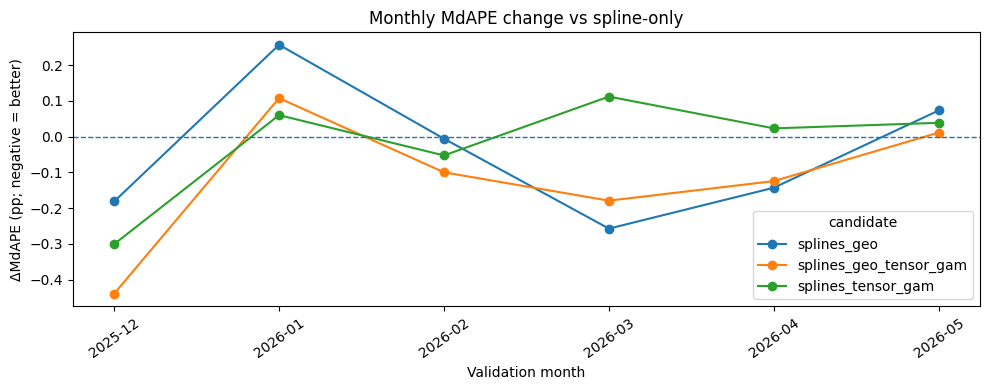

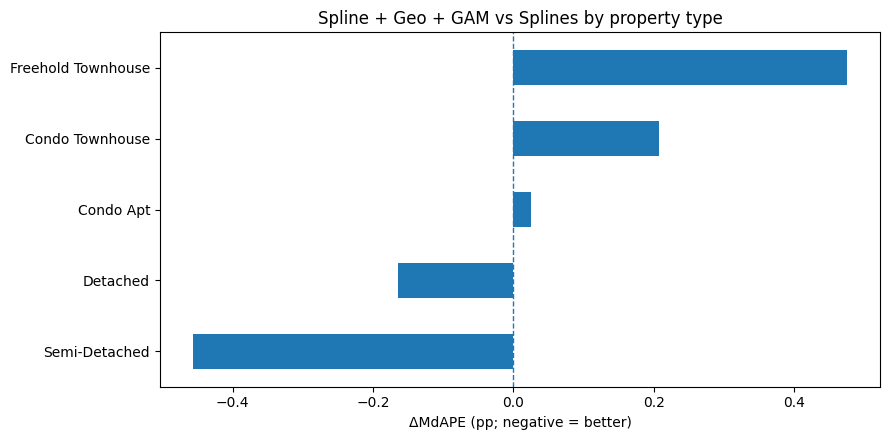

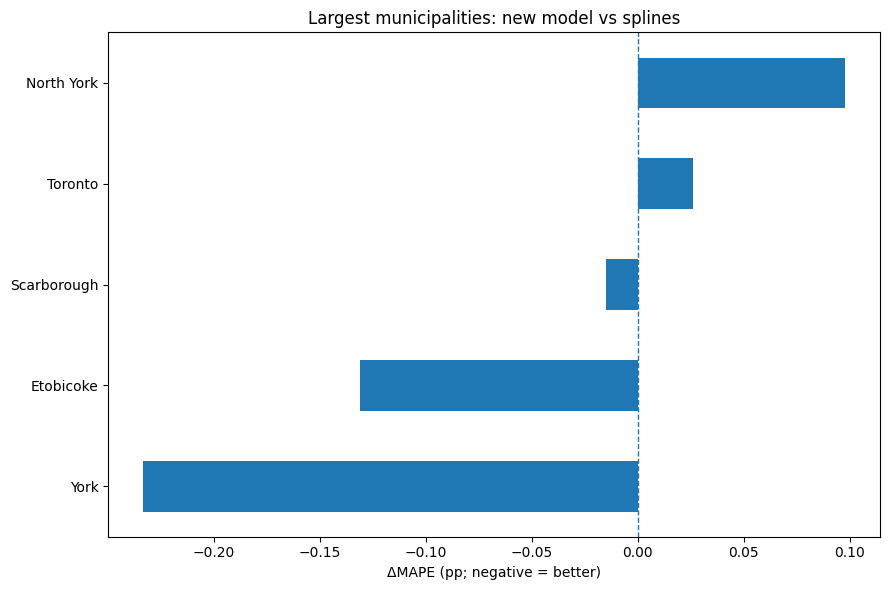


Analysis saved to: outputs\spacetime_full_spline_gam\diagnostics
Note: Subgroup results are exploratory. The validation period has already informed model selection.


In [10]:
# ==============================================================
# POST-EXPERIMENT ANALYSIS
# Full-strength spline / geographic context / Tensor GAM models
# No model fitting required.
# ==============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import data

RESULTS = Path("outputs/spacetime_full_spline_gam")
ANALYSIS = RESULTS / "diagnostics"
ANALYSIS.mkdir(parents=True, exist_ok=True)

N_BOOT = 2000
SEED = 42
MIN_TYPE = 100
MIN_REGION = 80

# Use in-memory predictions if available.
if "gam_predictions" in globals() and gam_predictions is not None:
    raw = gam_predictions.copy()
else:
    raw = pd.read_csv(
        RESULTS / "predictions.csv",
        dtype={"ml_num": "string", "month": "string"},
    )

MODELS = {
    "baseline": ("feature", "baseline"),
    "splines": ("feature", "splines"),
    "splines_geo": ("feature", "splines_geo"),
    "splines_tensor_gam": ("residual", "splines_tensor_gam"),
    "splines_geo_tensor_gam": ("residual", "splines_geo_tensor_gam"),
}

KEY = ["month", "ml_num"]

raw["month"] = raw["month"].astype(str)
raw["ml_num"] = raw["ml_num"].astype(str)

# --------------------------------------------------------------
# 1. Align predictions for identical homes across all models
# --------------------------------------------------------------

ref = raw.loc[
    (raw.arm == "feature") & (raw.variant == "splines")
].copy()

if ref.empty or ref.duplicated(KEY).any():
    raise ValueError("Spline reference predictions missing or duplicated")

ref = ref.set_index(KEY).sort_index()

frame = pd.DataFrame(index=ref.index)
frame["sold_price"] = pd.to_numeric(ref["sold_price"])

if (~np.isfinite(frame.sold_price) | (frame.sold_price <= 0)).any():
    raise ValueError("Invalid sale prices")

for name, (arm, variant) in MODELS.items():

    block = raw.loc[
        (raw.arm == arm) & (raw.variant == variant)
    ].copy()

    if block.empty or block.duplicated(KEY).any():
        raise ValueError(f"Missing or duplicate predictions: {name}")

    block = block.set_index(KEY).sort_index()

    if not block.index.equals(frame.index):
        raise ValueError(f"Property alignment mismatch: {name}")

    sold = block.sold_price.to_numpy(dtype=float)

    if not np.array_equal(
        sold, frame.sold_price.to_numpy(dtype=float)
    ):
        raise ValueError(f"Actual prices mismatch: {name}")

    pred = block.predicted_price.to_numpy(dtype=float)

    if not np.isfinite(pred).all() or (pred <= 0).any():
        raise ValueError(f"Invalid predictions: {name}")

    frame[f"pred_{name}"] = pred

    frame[f"signed_{name}"] = (
        100 * (pred - sold) / sold
    )

    frame[f"ape_{name}"] = np.abs(frame[f"signed_{name}"])

frame = frame.reset_index()

print(
    f"Validated {len(frame):,} aligned homes "
    f"across {frame.month.nunique()} months."
)


# --------------------------------------------------------------
# 2. Paired performance metrics
# --------------------------------------------------------------

def paired_stats(df, control, candidate):

    a = df[f"ape_{control}"].to_numpy(dtype=float)
    b = df[f"ape_{candidate}"].to_numpy(dtype=float)

    return {
        "homes": len(df),
        "control_mdape": np.median(a),
        "candidate_mdape": np.median(b),
        "delta_mdape_pp": np.median(b) - np.median(a),
        "delta_mape_pp": np.mean(b - a),
        "homes_improved_pct": 100 * np.mean(b < a),
        "control_signed_median": np.median(
            df[f"signed_{control}"]
        ),
        "candidate_signed_median": np.median(
            df[f"signed_{candidate}"]
        ),
    }


def paired_bootstrap(
    df, control, candidate, n_boot=N_BOOT, seed=SEED
):
    """
    Paired bootstrap, stratified by validation month.

    Important: The MdAPE difference is calculated as
    median(candidate APE) - median(control APE),
    NOT median(candidate APE - control APE).
    """

    a = df[f"ape_{control}"].to_numpy(dtype=float)
    b = df[f"ape_{candidate}"].to_numpy(dtype=float)

    groups = [
        np.flatnonzero(df.month.to_numpy() == month)
        for month in sorted(df.month.unique())
    ]

    rng = np.random.default_rng(seed)

    mdape_diffs = np.empty(n_boot)
    mape_diffs = np.empty(n_boot)

    for i in range(n_boot):

        ix = np.concatenate([
            rng.choice(group, size=len(group), replace=True)
            for group in groups
        ])

        mdape_diffs[i] = (
            np.median(b[ix]) - np.median(a[ix])
        )

        mape_diffs[i] = np.mean(b[ix] - a[ix])

    return {
        "mdape_ci_low": np.quantile(mdape_diffs, 0.025),
        "mdape_ci_high": np.quantile(mdape_diffs, 0.975),
        "mape_ci_low": np.quantile(mape_diffs, 0.025),
        "mape_ci_high": np.quantile(mape_diffs, 0.975),
    }


# --------------------------------------------------------------
# 3. Direct model comparisons
# --------------------------------------------------------------

PAIRS = [
    ("splines", "splines_geo_tensor_gam"),
    ("splines", "splines_geo"),
    ("splines", "splines_tensor_gam"),
    ("splines_geo", "splines_geo_tensor_gam"),
]

rows = []

for control, candidate in PAIRS:

    row = {
        "control": control,
        "candidate": candidate,
    }

    row.update(paired_stats(frame, control, candidate))
    row.update(paired_bootstrap(frame, control, candidate))

    rows.append(row)

summary = pd.DataFrame(rows)

summary.to_csv(
    ANALYSIS / "paired_full_comparison.csv",
    index=False,
)

print("\nDIRECT PAIRED COMPARISONS")
print("Negative delta = improvement")

display(summary.round(4))


# --------------------------------------------------------------
# 4. Month-block bootstrap sensitivity check
# --------------------------------------------------------------

def month_block_bootstrap(df, control, candidate, n_boot=N_BOOT):

    groups = [
        np.flatnonzero(df.month.to_numpy() == month)
        for month in sorted(df.month.unique())
    ]

    a = df[f"ape_{control}"].to_numpy()
    b = df[f"ape_{candidate}"].to_numpy()

    rng = np.random.default_rng(SEED + 1)
    results = np.empty(n_boot)

    for i in range(n_boot):

        sampled_months = rng.integers(
            0, len(groups), size=len(groups)
        )

        ix = np.concatenate([
            groups[j] for j in sampled_months
        ])

        results[i] = np.median(b[ix]) - np.median(a[ix])

    return np.quantile(results, [0.025, 0.975])


print("\nMONTH-BLOCK BOOTSTRAP SENSITIVITY")
print("Only six months; treat these ranges cautiously.")

for control, candidate in PAIRS[:2]:

    ci = month_block_bootstrap(frame, control, candidate)

    print(
        f"{candidate} vs {control}: "
        f"ΔMdAPE [{ci[0]:+.4f}, {ci[1]:+.4f}] pp"
    )


# --------------------------------------------------------------
# 5. Monthly stability of the improvements
# --------------------------------------------------------------

month_rows = []

for month, sub in frame.groupby("month", sort=True):

    for candidate in (
        "splines_geo",
        "splines_geo_tensor_gam",
        "splines_tensor_gam",
    ):

        row = {
            "month": month,
            "candidate": candidate,
        }

        row.update(
            paired_stats(sub, "splines", candidate)
        )

        month_rows.append(row)

by_month = pd.DataFrame(month_rows)

by_month.to_csv(
    ANALYSIS / "paired_by_month.csv",
    index=False,
)

print("\nMONTHLY COMPARISON AGAINST SPLINES")

display(by_month.round(4))


# --------------------------------------------------------------
# 6. Add house-type and geographic information
# --------------------------------------------------------------

sales = data.load("listings")

metadata_cols = [
    col for col in (
        "house_type_name",
        "municipality",
        "latitude",
        "longitude",
    )
    if col in sales.columns
]

meta = sales[
    ["ml_num", "date_sold"] + metadata_cols
].copy()

meta["month"] = (
    pd.to_datetime(meta.date_sold)
    .dt.to_period("M")
    .astype(str)
)

meta["ml_num"] = meta["ml_num"].astype(str)

meta = meta.drop(columns="date_sold")

if meta.duplicated(KEY).any():
    raise ValueError(
        "Duplicate month/property identifiers in source listings"
    )

frame = frame.merge(
    meta,
    on=KEY,
    how="left",
    validate="one_to_one",
)


def group_comparison(group_col, minimum):

    rows = []

    for label, sub in frame.groupby(group_col, dropna=True):

        if len(sub) < minimum:
            continue

        row = {group_col: label}

        row.update(
            paired_stats(
                sub,
                "splines",
                "splines_geo_tensor_gam",
            )
        )

        # How much does adding geographic context help?
        row["delta_geo_only_mdape_pp"] = (
            np.median(sub.ape_splines_geo)
            - np.median(sub.ape_splines)
        )

        row["delta_geo_only_mape_pp"] = np.mean(
            sub.ape_splines_geo - sub.ape_splines
        )

        # How much does the GAM help on top of geo?
        row["gam_delta_vs_geo_mdape_pp"] = (
            np.median(sub.ape_splines_geo_tensor_gam)
            - np.median(sub.ape_splines_geo)
        )

        row["gam_delta_vs_geo_mape_pp"] = np.mean(
            sub.ape_splines_geo_tensor_gam
            - sub.ape_splines_geo
        )

        rows.append(row)

    if not rows:
        return pd.DataFrame()

    return (
        pd.DataFrame(rows)
        .sort_values("homes", ascending=False)
        .reset_index(drop=True)
    )


# --------------------------------------------------------------
# 7. Property-type analysis
# --------------------------------------------------------------

if "house_type_name" in frame.columns:

    by_type = group_comparison(
        "house_type_name",
        MIN_TYPE,
    )

    by_type.to_csv(
        ANALYSIS / "paired_by_house_type.csv",
        index=False,
    )

    print("\nPROPERTY-TYPE COMPARISON")
    display(by_type.round(4))


# --------------------------------------------------------------
# 8. Geographic / municipality analysis
# --------------------------------------------------------------

if "municipality" in frame.columns:

    by_region = group_comparison(
        "municipality",
        MIN_REGION,
    )

    by_region.to_csv(
        ANALYSIS / "paired_by_municipality.csv",
        index=False,
    )

    print("\nMUNICIPALITY COMPARISON")
    print(f"Minimum {MIN_REGION} homes per municipality")

    display(by_region.round(4).head(25))


# --------------------------------------------------------------
# 9. Visualizations
# --------------------------------------------------------------

# Monthly MdAPE differences
monthly_plot = by_month.pivot(
    index="month",
    columns="candidate",
    values="delta_mdape_pp",
)

ax = monthly_plot.plot(
    marker="o",
    figsize=(10, 4),
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Monthly MdAPE change vs spline-only")
ax.set_ylabel("ΔMdAPE (pp; negative = better)")
ax.set_xlabel("Validation month")

plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    ANALYSIS / "monthly_mdape_delta.png",
    dpi=160,
)

plt.show()


# Property-type differences
if "house_type_name" in frame.columns and not by_type.empty:

    plot_type = by_type.sort_values("delta_mdape_pp")

    ax = plot_type.plot.barh(
        x="house_type_name",
        y="delta_mdape_pp",
        legend=False,
        figsize=(9, 4.5),
    )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title("Spline + Geo + GAM vs Splines by property type")
    ax.set_xlabel("ΔMdAPE (pp; negative = better)")
    ax.set_ylabel("")

    plt.tight_layout()

    plt.savefig(
        ANALYSIS / "house_type_mdape_delta.png",
        dpi=160,
    )

    plt.show()


# Geographic differences
if "municipality" in frame.columns and not by_region.empty:

    top_regions = (
        by_region.nlargest(15, "homes")
        .sort_values("delta_mape_pp")
    )

    ax = top_regions.plot.barh(
        x="municipality",
        y="delta_mape_pp",
        legend=False,
        figsize=(9, 6),
    )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title("Largest municipalities: new model vs splines")
    ax.set_xlabel("ΔMAPE (pp; negative = better)")
    ax.set_ylabel("")

    plt.tight_layout()

    plt.savefig(
        ANALYSIS / "municipality_mape_delta.png",
        dpi=160,
    )

    plt.show()

print("\nAnalysis saved to:", ANALYSIS)
print(
    "Note: Subgroup results are exploratory. The validation "
    "period has already informed model selection."
)